# 43 — SMALL no subconjunto D: por que o MEL não separa SMALL de LARGE?

**Pergunta.** Na análise de MEL e HHT da classe SMALL (apresentação `20261116-classe-small`), apareceu algo estranho: no **subconjunto D** (sem CPA, navio a 250–500 m), o MEL **não separa SMALL de LARGE em nenhuma faixa**, mas separa MEDIUM de LARGE. Em A e C, os dois se separam do LARGE.

**Três passos para entender:**
1. **Quem mudou no D: o SMALL ou o LARGE?** Cada classe no D contra a mesma classe em A+C.
2. **O mesmo navio soa diferente no D?** Navios gravados no D e em A/C, comparados com eles mesmos.
3. **O D tem algum grupo de SMALL que apaga a diferença?** Subgrupos (tipo, navios só no D) contra o LARGE do D.

**Unidade de análise:** o navio (média das suas gravações). **Medidas de "grave forte"** (todas independentes do ganho do gravador):
- **LOFAR 31–86 Hz:** dB acima do fundo TPSW na banda que mais identifica LARGE (NB35);
- **MEL grave − agudo:** média do MEL L2 abaixo de 1 kHz menos a média de 1 a 6 kHz;
- **psd24k grave relativo:** dB em 31–125 Hz menos dB em 1–4 kHz.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, wilcoxon, false_discovery_control
warnings.filterwarnings('ignore')
try:
    from IPython.display import display
except ImportError:
    display = print
ROOT = next(os.path.abspath(p) for p in ('.', '..') if os.path.exists(os.path.join(p, 'scratch', 'eval_ship_split_5x2cv.py')))
os.chdir(ROOT); sys.path.insert(0, os.path.join(ROOT, 'scratch'))
from eval_ship_split_5x2cv import metadata
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 110})
pd.set_option('display.precision', 3); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
P = 'data/iara_processed/'
COR = {'SMALL': '#2a78d6', 'MEDIUM': '#eb6834', 'LARGE': '#1baf7a'}

m = metadata(); m.index = m.index.map(int)
m = m[m.Target < 3].copy()                                    # só gravações de navio (A–D)
m['classe'] = m.Target.map({0: 'SMALL', 1: 'MEDIUM', 2: 'LARGE'}); m['ship'] = m['Ship ID'].astype(str)
m['Length'] = pd.to_numeric(m['Length'], errors='coerce')
m['grupo'] = np.where(m.Dataset == 'D', 'D', np.where(m.Dataset == 'B', 'B', 'A+C'))

# espectro médio de cada gravação, em três representações
lofar = pd.read_pickle(P + 'cache_lofar_espectro_medio.pkl'); lofar.index = lofar.index.map(int)
FL = np.arange(1024) * 16000 / 2048                            # 1.024 faixas de 7,8 Hz (dB acima do fundo TPSW)
mel = pd.read_pickle(P + 'cache_mel_espectro_medio.pkl')['L2 (modelos)']
import librosa
FM = librosa.mel_frequencies(n_mels=258, fmin=0, fmax=8000)[1:-1]   # centro das 256 bandas mel
_ps = pd.read_pickle(P + 'cache_psd24k_resumo.pkl'); FP = _ps['freqs']
psd = _ps['psd_db'] if isinstance(_ps['psd_db'], pd.DataFrame) else pd.DataFrame(_ps['psd_db']); psd.index = psd.index.map(int)
_k = (FP >= 20) & (FP <= 8000); FP8 = FP[_k]
PF = psd.loc[:, _k]; PF = PF.sub(PF.mean(1), axis=0)           # forma do psd24k: dB menos a média da gravação (sem ganho)

def banda(X, F, lo, hi):
    return X.loc[:, (F >= lo) & (F < hi)].mean(1)

# três medidas-resumo de "grave forte" (todas independentes do ganho)
MED = pd.DataFrame({
    'LOFAR 31–86 Hz': banda(lofar, FL, 31, 86),
    'MEL grave − agudo': banda(mel, FM, 0, 1000) - banda(mel, FM, 1000, 6000),
    'psd24k grave relativo': banda(PF, FP8, 31, 125) - banda(PF, FP8, 1000, 4000)})
UNID = {'LOFAR 31–86 Hz': 'dB acima do fundo', 'MEL grave − agudo': 'L2 média < 1 kHz menos 1–6 kHz',
        'psd24k grave relativo': 'dB, 31–125 Hz menos 1–4 kHz'}
REPS = {'LOFAR (20 Hz–6 kHz)': lofar.loc[:, (FL >= 20) & (FL <= 6000)], 'MEL L2': mel, 'psd24k forma (20 Hz–8 kHz)': PF}

def nav(X, ids):
    """média por navio: cada navio pesa 1"""
    ids = [i for i in ids if i in X.index]
    return X.loc[ids].groupby(m.loc[ids, 'ship'].values).mean()

def sel(c, ds):
    return m.index[(m.classe == c) & m.Dataset.isin(list(ds))]

def faixas(A, B):
    """Mann-Whitney faixa a faixa entre navios + FDR: % de faixas com q < 0,05 e AUC por faixa"""
    U, p = mannwhitneyu(A.values, B.values, axis=0)
    return 100 * (false_discovery_control(p) < .05).mean(), U / (len(A) * len(B))

print('Navios por classe e subconjunto:')
display(m.groupby(['classe', 'Dataset']).ship.nunique().unstack()[list('ABCD')])

Navios por classe e subconjunto:


Dataset,A,B,C,D
classe,,,,
LARGE,177,31,140,123
MEDIUM,35,30,37,40
SMALL,36,20,35,54


## 0. O efeito existe nas três representações?

In [2]:
# O efeito existe nas três representações? % de faixas com diferença (q < 0,05) por subconjunto
rows = []
for nome, X in REPS.items():
    for ds in 'ABCD':
        for a, b in (('SMALL', 'LARGE'), ('MEDIUM', 'LARGE'), ('SMALL', 'MEDIUM')):
            A, B = nav(X, sel(a, ds)), nav(X, sel(b, ds))
            pct, auc = faixas(A, B)
            rows.append({'representação': nome, 'comparação': f'{a} × {b}', 'subconjunto': ds, '% faixas': pct})
EFEITO = pd.DataFrame(rows).pivot_table(index=['representação', 'comparação'], columns='subconjunto', values='% faixas').round(0)
print('% das faixas com q < 0,05 (navio = unidade):'); display(EFEITO)

% das faixas com q < 0,05 (navio = unidade):


subconjunto                                   A    B     C     D
representação              comparação                           
LOFAR (20 Hz–6 kHz)        MEDIUM × LARGE  20.0  0.0  18.0   2.0
                           SMALL × LARGE    4.0  0.0  18.0   0.0
                           SMALL × MEDIUM   0.0  0.0   0.0   1.0
MEL L2                     MEDIUM × LARGE  92.0  0.0  91.0  80.0
                           SMALL × LARGE   84.0  0.0  94.0   0.0
                           SMALL × MEDIUM   0.0  0.0   0.0   0.0
psd24k forma (20 Hz–8 kHz) MEDIUM × LARGE  59.0  0.0  57.0   0.0
                           SMALL × LARGE   66.0  0.0  81.0   0.0
                           SMALL × MEDIUM   0.0  0.0   0.0   0.0

**Leitura.**
- **O achado se confirma no MEL:** no D, SMALL × LARGE tem 0% das faixas com diferença, contra 84% em A e 94% em C; MEDIUM × LARGE continua com 80%.
- **Mas o D enfraquece tudo, não só o SMALL:** no psd24k, MEDIUM × LARGE também cai a 0% no D (contra 59% em A); no LOFAR, a 2% (contra 20%). O MEL é só a representação em que o MEDIUM ainda passa do limiar.
- **No B nada separa nada** (0% e 0%), em parte porque o B tem poucos navios (ver a primeira tabela).
- SMALL × MEDIUM: 0% no D, como em todos os subconjuntos.

## 1. Quem mudou no D: o SMALL ou o LARGE?

,,mediana A+C,mediana B,mediana D,AUC (D > A+C),p
medida,classe,,,,,
LOFAR 31–86 Hz,SMALL,5.195,4.746,5.248,0.537,0.501
MEL grave − agudo,SMALL,0.016,0.012,0.015,0.487,0.814
psd24k grave relativo,SMALL,18.166,16.297,19.082,0.537,0.498
LOFAR 31–86 Hz,MEDIUM,4.303,4.451,3.902,0.469,0.600
MEL grave − agudo,MEDIUM,0.014,0.013,0.013,0.481,0.748
psd24k grave relativo,MEDIUM,17.407,18.003,18.306,0.510,0.871
LOFAR 31–86 Hz,LARGE,7.647,4.885,6.172,0.374,0.000
MEL grave − agudo,LARGE,0.026,0.012,0.018,0.351,0.000
psd24k grave relativo,LARGE,25.520,19.058,21.521,0.371,0.000


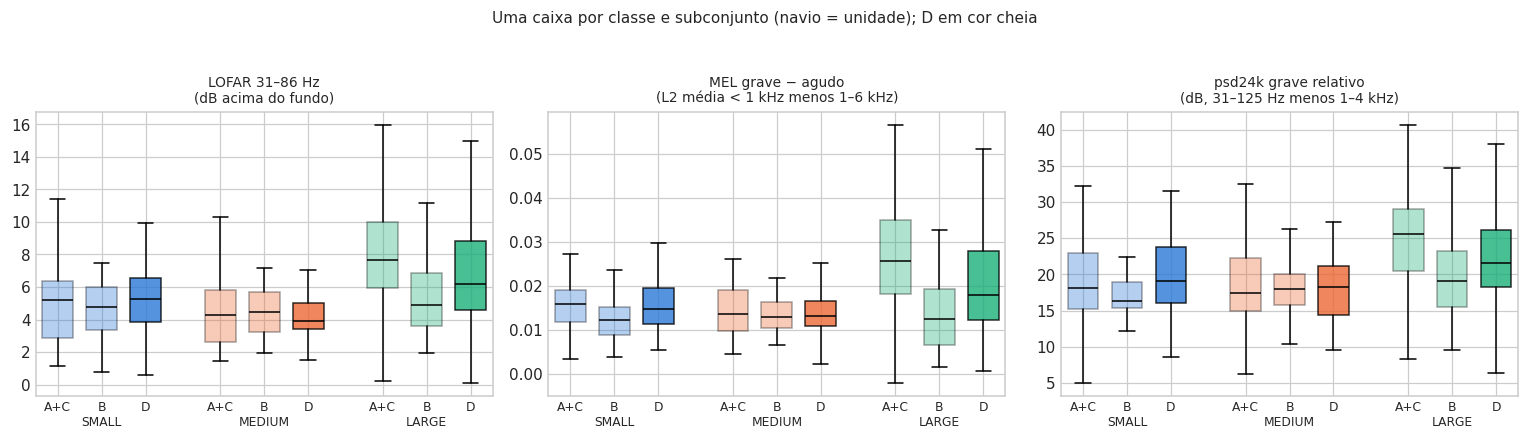

In [3]:
# Passo 1: cada classe no D (e no B) contra a mesma classe em A+C
rows = []
for c in ('SMALL', 'MEDIUM', 'LARGE'):
    for med in MED:
        x, y, b = (nav(MED[[med]], sel(c, g))[med] for g in ('D', 'AC', 'B'))
        U, p = mannwhitneyu(x, y)
        rows.append({'classe': c, 'medida': med, 'mediana A+C': y.median(), 'mediana B': b.median(), 'mediana D': x.median(),
                     'AUC (D > A+C)': U / (len(x) * len(y)), 'p': p})
PASSO1 = pd.DataFrame(rows).set_index(['medida', 'classe'])
display(PASSO1.round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for j, med in enumerate(MED):
    pos = 0; ticks, labs = [], []
    for c in ('SMALL', 'MEDIUM', 'LARGE'):
        for g in ('A+C', 'B', 'D'):
            v = nav(MED[[med]], sel(c, g.replace('+', '')))[med]
            bp = ax[j].boxplot(v, positions=[pos], widths=.7, showfliers=False, patch_artist=True)
            bp['boxes'][0].set(facecolor=COR[c], alpha=.35 if g != 'D' else .8); bp['medians'][0].set(color='k')
            ticks.append(pos); labs.append(f'{g}\n{c}' if g == 'B' else f'{g}\n'); pos += 1
        pos += .7
    ax[j].set_xticks(ticks); ax[j].set_xticklabels(labs, fontsize=8); ax[j].set_title(f'{med}\n({UNID[med]})', fontsize=9)
plt.suptitle('Uma caixa por classe e subconjunto (navio = unidade); D em cor cheia', y=1.04, fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.**
- **Quem mudou foi o LARGE.** O LARGE do D tem menos grave que o de A+C nas três medidas (LOFAR 31–86 Hz: 7,65 → 6,17 dB, AUC 0,37, p < 0,001); no B, ainda menos (4,88 dB).
- **O SMALL não mudou** (LOFAR 5,20 → 5,25 dB, p = 0,501), **nem o MEDIUM** (4,30 → 3,90 dB, p = 0,600).
- Com o LARGE descendo e o SMALL parado, a distância entre os dois encolhe. O MEDIUM do D fica um pouco mais baixo que o SMALL, e por isso ainda passa do limiar no MEL.

## 2. O mesmo navio soa diferente no D?

,,navios no D e em A/C,Δ mediano (D − A/C),% navios com D maior,p (Wilcoxon)
medida,classe,,,,
LOFAR 31–86 Hz,SMALL,28,0.564,57.143,0.399
MEL grave − agudo,SMALL,28,-0.002,39.286,0.109
psd24k grave relativo,SMALL,28,-0.273,42.857,0.902
LOFAR 31–86 Hz,MEDIUM,26,0.053,53.846,0.452
MEL grave − agudo,MEDIUM,26,0.002,61.538,0.340
psd24k grave relativo,MEDIUM,26,0.965,61.538,0.208
LOFAR 31–86 Hz,LARGE,22,-0.523,45.455,0.799
MEL grave − agudo,LARGE,22,0.000,50.000,0.750
psd24k grave relativo,LARGE,22,-0.394,50.000,0.750


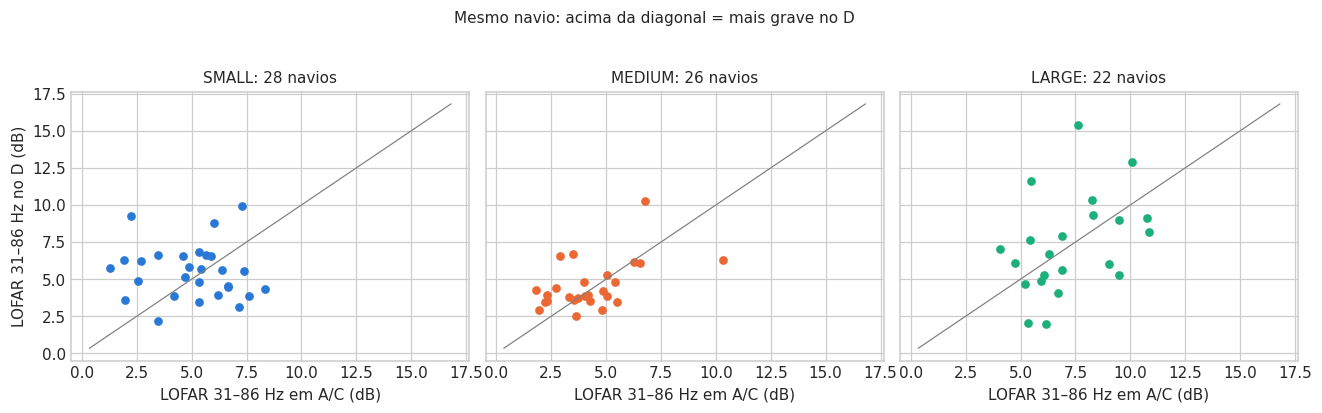

In [4]:
# Passo 2: o mesmo navio, gravado no D e em A/C (teste de Wilcoxon pareado)
rows, PARES = [], {}
for c in ('SMALL', 'MEDIUM', 'LARGE'):
    d, ac = nav(MED, sel(c, 'D')), nav(MED, sel(c, 'AC'))
    com = d.index.intersection(ac.index); PARES[c] = (ac.loc[com], d.loc[com])
    for med in MED:
        dif = d.loc[com, med] - ac.loc[com, med]
        rows.append({'classe': c, 'medida': med, 'navios no D e em A/C': len(com), 'Δ mediano (D − A/C)': dif.median(),
                     '% navios com D maior': 100 * (dif > 0).mean(), 'p (Wilcoxon)': wilcoxon(dif).pvalue})
PASSO2 = pd.DataFrame(rows).set_index(['medida', 'classe'])
display(PASSO2.round(3))

med = 'LOFAR 31–86 Hz'
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for j, c in enumerate(('SMALL', 'MEDIUM', 'LARGE')):
    a, d = PARES[c]
    ax[j].scatter(a[med], d[med], color=COR[c], s=22)
    lo, hi = MED[med].quantile([.01, .99]); ax[j].plot([lo, hi], [lo, hi], color='gray', lw=.8)
    ax[j].set_title(f'{c}: {len(a)} navios', fontsize=10); ax[j].set_xlabel(f'{med} em A/C (dB)')
ax[0].set_ylabel(f'{med} no D (dB)')
plt.suptitle('Mesmo navio: acima da diagonal = mais grave no D', y=1.03, fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.**
- **O mesmo navio não muda entre A/C e D**, em nenhuma classe e em nenhuma medida (menor p = 0,11).
- LARGE: 22 navios, Δ mediano -0,52 dB (p = 0,799). SMALL: 28 navios, Δ 0,56 dB (p = 0,399).
- Os pontos ficam longe da diagonal nos dois sentidos: **o mesmo navio varia muito de uma gravação para outra**, então o teste só detectaria um efeito grande.
- Então a queda do grave do LARGE no D **não parece efeito da distância nem da falta do CPA** sobre o mesmo navio: é que os LARGE gravados no D são, em boa parte, **outros navios** (próxima seção).

### 2.1 Os LARGE do D são outros navios?

In [5]:
# O LARGE do D: são outros navios? Comprimento e grave dos navios LARGE por subconjunto
L = m[m.classe == 'LARGE']; ac_ships, d_ships = set(L[L.grupo == 'A+C'].ship), set(L[L.grupo == 'D'].ship)
rows = []
for nome, ix in (('A+C: navios só em A+C', L.index[(L.grupo == 'A+C') & ~L.ship.isin(d_ships)]),
                 ('A+C: navios também no D', L.index[(L.grupo == 'A+C') & L.ship.isin(d_ships)]),
                 ('D: navios também em A+C', L.index[(L.grupo == 'D') & L.ship.isin(ac_ships)]),
                 ('D: navios só no D', L.index[(L.grupo == 'D') & ~L.ship.isin(ac_ships)])):
    v = nav(MED, ix)
    rows.append({'grupo de LARGE': nome, 'navios': len(v), 'comprimento mediano (m)': L.loc[ix].drop_duplicates('ship').Length.median(),
                 **{med: v[med].median() for med in MED}})
LARGE_D = pd.DataFrame(rows).set_index('grupo de LARGE')
display(LARGE_D.round(2))
from scipy.stats import spearmanr
_v = nav(MED, L.index).join(L.drop_duplicates('ship').set_index('ship').Length)
RHO_L = spearmanr(_v.Length, _v['LOFAR 31–86 Hz'], nan_policy='omit')
print(f'Entre os LARGE, comprimento × LOFAR 31–86 Hz: ρ = {RHO_L.statistic:.2f} (p = {RHO_L.pvalue:.3f})')
_t = L.drop_duplicates(['ship', 'grupo']); TIPOS_L = pd.crosstab(_t['DETAILED TYPE'], _t.grupo)[['A+C', 'D']]
TIPOS_L = (100 * TIPOS_L / TIPOS_L.sum()).round(0).sort_values('A+C', ascending=False).head(7)
print('% dos navios LARGE por tipo:'); display(TIPOS_L)

,navios,comprimento mediano (m),LOFAR 31–86 Hz,MEL grave − agudo,psd24k grave relativo
grupo de LARGE,,,,,
A+C: navios só em A+C,272,272.0,7.75,0.03,25.60
A+C: navios também no D,22,201.0,6.78,0.02,24.17
D: navios também em A+C,22,201.0,6.87,0.02,20.88
D: navios só no D,101,200.0,6.14,0.02,21.55


Entre os LARGE, comprimento × LOFAR 31–86 Hz: ρ = 0.08 (p = 0.086)
% dos navios LARGE por tipo:


grupo,A+C,D
DETAILED TYPE,,
Bulk Carrier,41.0,31.0
Container Ship,21.0,23.0
Crude Oil Tanker,11.0,10.0
Oil/Chemical Tanker,10.0,10.0
General Cargo,5.0,11.0
Ore Carrier,4.0,0.0
Passenger Ship,2.0,4.0


**Leitura.**
- **101 dos 123 navios LARGE do D só aparecem no D**, e são menores: comprimento mediano de 200 m, contra 272 m dos LARGE que só aparecem em A+C.
- Os LARGE que só aparecem em A+C têm o grave mais forte (7,75 dB no LOFAR); os LARGE do D, só no D, 6,14 dB.
- Os 22 navios gravados nos dois têm grave intermediário e igual nos dois lugares (6,78 e 6,87 dB): coerente com o passo 2.
- **Não é só o comprimento:** entre todos os LARGE, comprimento e grave quase não se relacionam (ρ = 0,08, p = 0,086). O comprimento só mostra que são navios diferentes; a causa pode ser tipo, carga, velocidade ou propulsão.
- Nos tipos, o D tem relativamente mais carga geral e menos graneleiros.

## 3. O D tem algum grupo de SMALL que apaga a diferença?

Cada subgrupo de SMALL contra o LARGE **do mesmo subconjunto**, faixa a faixa no MEL L2. AUC abaixo de 0,5 = o LARGE tem mais.

In [6]:
# Passo 3a: SMALL do D por subgrupo contra LARGE do D (MEL L2, faixa a faixa)
LD, LAC = nav(mel, sel('LARGE', 'D')), nav(mel, sel('LARGE', 'AC'))
sD = m[(m.classe == 'SMALL') & (m.Dataset == 'D')]; sAC = m[(m.classe == 'SMALL') & m.Dataset.isin(['A', 'C'])]
em_ac = set(sAC.ship)
def subgrupos(s):
    t = s['DETAILED TYPE']
    return {'todas as SMALL': s.index, 'lanchas de prático': s.index[t == 'Pilot Vessel'], 'rebocadores': s.index[t == 'Tug'],
            'pesca': s.index[t == 'Fishing Vessel']}
rows = []
for onde, s, L in (('D', sD, LD), ('A+C', sAC, LAC)):
    g = subgrupos(s)
    if onde == 'D':
        g.update({'navios também gravados em A/C': s.index[s.ship.isin(em_ac)], 'navios só no D': s.index[~s.ship.isin(em_ac)]})
    g['MEDIUM (referência)'] = sel('MEDIUM', onde.replace('+', ''))
    for nome, ix in g.items():
        A = nav(mel, ix); pct, auc = faixas(A, L)
        rows.append({'subconjunto': onde, 'grupo contra LARGE': nome, 'navios': len(A), '% faixas q < 0,05': pct,
                     'AUC mediana < 1 kHz': np.median(auc[FM < 1000]), 'AUC mediana > 1 kHz': np.median(auc[FM > 1000])})
SUB = pd.DataFrame(rows).set_index(['subconjunto', 'grupo contra LARGE'])
display(SUB.round(2))

# Passo 3b: quantos navios SMALL ficam acima da mediana do LARGE do mesmo subconjunto?
rows = []
for med in MED:
    for g in ('A+C', 'D'):
        s, L = nav(MED[[med]], sel('SMALL', g.replace('+', '')))[med], nav(MED[[med]], sel('LARGE', g.replace('+', '')))[med]
        rows.append({'medida': med, 'subconjunto': g, 'mediana SMALL': s.median(), 'mediana LARGE': L.median(),
                     '% SMALL acima da mediana LARGE': 100 * (s > L.median()).mean()})
ACIMA = pd.DataFrame(rows).set_index(['medida', 'subconjunto'])
display(ACIMA.round(2))

# Passo 3c: os navios SMALL do D mais parecidos com LARGE (maior grave no LOFAR)
info = m.groupby('ship').agg(tipo=('DETAILED TYPE', 'first'), comprimento=('Length', 'first'))
nD = sD.groupby('ship').size().rename('gravações no D')
TOP = nav(MED, sD.index).join(info).join(nD).assign(**{'também em A/C': lambda t: t.index.isin(em_ac)})
TOP = TOP.sort_values('LOFAR 31–86 Hz', ascending=False)
print(f"Navios SMALL do D com mais grave (LOFAR 31–86 Hz); mediana do LARGE do D = {nav(MED, sel('LARGE', 'D'))['LOFAR 31–86 Hz'].median():.2f} dB")
display(TOP.head(10).round(2))
print('Mediana por tipo, SMALL do D:'); display(TOP.groupby('tipo')[list(MED)].median().join(TOP.tipo.value_counts().rename('navios')).sort_values('navios', ascending=False).head(4).round(2))

navios  % faixas q < 0,05  AUC mediana < 1 kHz  AUC mediana > 1 kHz
subconjunto grupo contra LARGE                                                                                
D           todas as SMALL                     54               0.00                 0.45                 0.58
            lanchas de prático                 10               0.39                 0.46                 0.57
            rebocadores                        21               0.00                 0.42                 0.60
            pesca                              11               0.00                 0.52                 0.47
            navios também gravados em A/C      28               3.91                 0.43                 0.62
            navios só no D                     26               0.00                 0.47                 0.54
            MEDIUM (referência)                40              80.47                 0.40                 0.64
A+C         todas as SMALL                     58              94.92                 0.32                 0.73
            lanchas de prático                 15              57.03                 0.36                 0.73
            rebocadores                        23              87.11                 0.31                 0.70
            pesca                              12               1.17                 0.39                 0.69
            MEDIUM (referência)                58              94.53                 0.30                 0.73

mediana SMALL  mediana LARGE  % SMALL acima da mediana LARGE
medida                subconjunto                                                              
LOFAR 31–86 Hz        A+C                   5.20           7.65                           10.34
                      D                     5.25           6.17                           33.33
MEL grave − agudo     A+C                   0.02           0.03                           10.34
                      D                     0.01           0.02                           38.89
psd24k grave relativo A+C                  18.17          25.52                           10.34
                      D                    19.08          21.52                           35.19

Navios SMALL do D com mais grave (LOFAR 31–86 Hz); mediana do LARGE do D = 6.17 dB


,LOFAR 31–86 Hz,MEL grave − agudo,psd24k grave relativo,tipo,comprimento,gravações no D,também em A/C
460,11.52,0.04,28.95,Fishing Vessel,19,1,False
511,9.93,0.02,28.42,Tug,24,1,True
342,9.83,0.03,31.51,Tug,19,1,False
503,9.48,0.03,29.91,Fishing Vessel,48,1,False
44,9.24,0.02,28.76,Fishing Vessel,22,1,True
423,8.82,0.02,29.24,Tug,34,1,True
631,8.07,0.03,23.95,Tug,25,1,False
309,7.46,0.01,21.21,Tug,19,1,False
580,6.85,0.02,17.53,Fishing Vessel,18,2,True
459,6.75,0.03,28.54,Fishing Vessel,8,2,False


Mediana por tipo, SMALL do D:


,LOFAR 31–86 Hz,MEL grave − agudo,psd24k grave relativo,navios
tipo,,,,
Tug,4.83,0.01,17.36,21
Fishing Vessel,6.52,0.02,23.96,11
Pilot Vessel,5.66,0.01,18.88,10
Offshore Supply Ship,6.22,0.01,17.22,3


**Leitura.**
- **Nenhum subgrupo de SMALL do D se separa do LARGE do D** no MEL: lanchas 0,4%, rebocadores 0%, pesca 0%, navios também gravados em A/C 4%, só no D 0%. Não é um grupo "estranho" de SMALL que apaga a diferença.
- Em A+C, ao contrário, rebocadores (87%) e lanchas (57%) se separam do LARGE; a **pesca não se separa nem em A+C** (1%): os pesqueiros têm grave parecido com o do LARGE em todos os subconjuntos.
- **A diferença entre SMALL e MEDIUM no D é pequena:** AUC mediana abaixo de 1 kHz 0,45 (SMALL × LARGE) contra 0,40 (MEDIUM × LARGE). É uma questão de limiar, não um comportamento oposto.
- **Proporção de SMALL acima da mediana do LARGE** (LOFAR 31–86 Hz): 10% em A+C, 33% no D, porque a mediana do LARGE desceu (7,65 → 6,17 dB) e a do SMALL não.
- Os SMALL do D com mais grave são sobretudo **pesqueiros e rebocadores com poucas gravações**; as lanchas de prático quase não aparecem no topo.

## 5. Conclusões

1. **O SMALL do D é igual ao SMALL de A e C.** Ele não ganha grave longe do hidrofone, nem como classe (passo 1) nem dentro do mesmo navio (passo 2).
2. **Quem muda é o LARGE:** o LARGE do D tem menos grave porque é formado, em boa parte, por **outros navios** (também menores: 200 m contra 272 m), e não porque o mesmo navio soa diferente a 250–500 m sem CPA.
3. **O "D não separa SMALL de LARGE, mas separa MEDIUM" é um efeito de limiar:** no D, todas as separações ficam mais fracas (no psd24k e no LOFAR, nem MEDIUM × LARGE passa). No MEL, o MEDIUM do D fica um pouco mais longe do LARGE e passa; o SMALL fica um pouco mais perto e não passa.
4. **Nenhum subgrupo explica sozinho** (lanchas, rebocadores, pesca, navios só no D). Os pesqueiros não se separam do LARGE em lugar nenhum, o que reforça que "grave forte" não é exclusividade de navio grande.
5. **Consequência para o modelo:** a pista do LARGE (grave em 31–86 Hz) depende de **quais** LARGE foram gravados: os LARGE do D se parecem mais com os navios < 100 m. Isso é composição da base, não geometria da gravação, e não cria uma assinatura nova de SMALL.
6. **Limite:** o teste pareado do passo 2 tem só 22 navios LARGE e 28 SMALL; um efeito pequeno de distância pode existir sem ser detectado.